# 01 · Reconciliation with official DfT totals (RAS0101)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryam843/uk-road-accident-analytics/blob/main/notebooks/01_reconciliation.ipynb)

This is the data-quality proof for the whole project. Yearly totals from the cleaned pipeline
output are compared with DfT table **RAS0101** (*Reported road collisions, casualties and
vehicles involved, Great Britain*).

What RAS0101 publishes (sheet → column):

| Measure | RAS0101 | Pipeline |
|---|---|---|
| All collisions | Collisions → All collisions | rows in `collisions_2005_2019.parquet` |
| Fatal collisions | Collisions → Fatal | `collision_severity == 1` |
| Fatal or serious collisions (unadjusted) | Collisions → FSC (unadjusted) | severity 1 or 2 |
| Fatal or serious collisions (adjusted) | Collisions → FSC (adjusted) | fatal + Σ `collision_adjusted_serious` |
| Serious collisions (unadjusted / adjusted) | FSC − Fatal (derived) | same derivation |
| People killed | Casualties → All road users (killed) | `casualty_severity == 1` |
| All casualties | Casualties → All road users (all severities) | rows in `casualties_2005_2019.parquet` |

RAS0101 does not publish serious **casualties** on their own, so serious injury is checked at
collision level.

**Acceptance rule:** yearly collision counts must match within **0.5%**. **Result (this run):** every measure matches RAS0101 exactly in every year 2005-2019. The
largest yearly difference in collision counts is 0.000%, and the summary table shows 0.000 for
all eight measures, including the adjusted fatal-or-serious count.

In [1]:
# Setup: works from the repo root, from notebooks/, or on Google Colab.
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src/config.py").exists():
    if not Path("uk-road-accident-analytics").exists():
        !git clone -q https://github.com/maryam843/uk-road-accident-analytics.git
    %cd uk-road-accident-analytics
    %pip install -q -r requirements.txt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import logging

import matplotlib.pyplot as plt
import pandas as pd

from src import clean, config, evaluate

config.setup_logging(logging.INFO)
evaluate.apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

DATA_DIR = config.get_data_dir()
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
if not (PROCESSED / config.COLLISIONS_PARQUET).exists():
    # Fresh runtime (e.g. Colab): download (several GB) and clean. Takes a while, once.
    from src import download

    download.main([])
    clean.run()
print("DATA_DIR =", config.display_path(DATA_DIR))

DATA_DIR = data


## Cleaning log
Counts recorded by `python -m src.clean` (duplicates dropped, invalid speed limits, flagged coordinates, ...).

In [3]:
import json

clean_log = json.loads((PROCESSED / config.CLEAN_LOG_FILE).read_text())
coll_log = {k: v for k, v in clean_log["collisions"].items() if k != "decode"}
print(json.dumps(coll_log, indent=2))
print(json.dumps({k: v for k, v in clean_log["casualties"].items() if k != "decode"}, indent=2))
decode = pd.DataFrame(clean_log["collisions"]["decode"]).T
display(decode.sort_values("missing_to_nan", ascending=False))

{
  "rows_read": 9116625,
  "non_numeric_values_coerced": 0,
  "rows_in_study_window": 2287427,
  "dedup": {
    "duplicate_index_rows_dropped": 0,
    "exact_duplicate_rows": 0,
    "conflicting_duplicate_rows": 0
  },
  "invalid_speed_limit": 116,
  "datetime": {
    "unparsed_dates": 0,
    "missing_or_bad_times": 0
  },
  "weekday_code_vs_date_mismatch": 0,
  "invalid_coordinates_flagged": 247,
  "rows_out": 2287427
}
{
  "rows_read": 12102133,
  "non_numeric_values_coerced": 0,
  "rows_in_study_window": 3069041,
  "duplicate_casualty_rows_dropped": 0,
  "rows_out": 3069041
}


,missing_to_nan,unmapped_codes
junction_control,861527,0
trunk_road_flag,241371,0
second_road_class,17695,0
road_surface_conditions,7717,0
special_conditions_at_site,6178,0
junction_detail_historic,2903,0
did_police_officer_attend_scene_of_collision,280,0
weather_conditions,194,0
light_conditions,15,0
road_type,1,0


## Pipeline vs RAS0101

In [4]:
yearly = pd.read_parquet(PROCESSED / config.YEARLY_PARQUET)
official = clean.load_ras0101(RAW / config.RAS0101_RAW_FILE).loc[config.YEAR_MIN:config.YEAR_MAX]

for frame in (yearly, official):
    frame["serious_collisions_derived"] = frame["ksi_collisions"] - frame["fatal_collisions"]
    frame["serious_collisions_adjusted_derived"] = (
        frame["ksi_collisions_adjusted"] - frame["fatal_collisions"]
    )

MEASURES = {
    "collisions": "All collisions",
    "fatal_collisions": "Fatal collisions",
    "ksi_collisions": "Fatal or serious collisions (unadjusted)",
    "ksi_collisions_adjusted": "Fatal or serious collisions (adjusted)",
    "serious_collisions_derived": "Serious collisions (unadjusted)",
    "serious_collisions_adjusted_derived": "Serious collisions (adjusted)",
    "killed": "People killed",
    "casualties": "All casualties",
}
rows = []
for col, label in MEASURES.items():
    for year in official.index:
        p, o = float(yearly.loc[year, col]), float(official.loc[year, col])
        rows.append({"measure": label, "year": year, "pipeline": p, "ras0101": o,
                     "difference": p - o, "pct_difference": 100 * (p - o) / o})
recon = pd.DataFrame(rows)
recon.to_csv(PROCESSED / "reconciliation_ras0101.csv", index=False)

In [5]:
collision_table = recon[recon["measure"] == "All collisions"].set_index("year")
display(collision_table[["pipeline", "ras0101", "difference", "pct_difference"]]
        .style.format({"pipeline": "{:,.0f}", "ras0101": "{:,.0f}", "difference": "{:+,.0f}",
                       "pct_difference": "{:+.3f}%"}))

,pipeline,ras0101,difference,pct_difference
year,,,,
2005,"198,735","198,735",+0,+0.000%
2006,"189,161","189,161",+0,+0.000%
2007,"182,115","182,115",+0,+0.000%
2008,"170,591","170,591",+0,+0.000%
2009,"163,554","163,554",+0,+0.000%
2010,"154,414","154,414",+0,+0.000%
2011,"151,474","151,474",+0,+0.000%
2012,"145,571","145,571",+0,+0.000%
2013,"138,660","138,660",+0,+0.000%


In [6]:
summary = recon.groupby("measure", sort=False).agg(
    max_abs_pct_difference=("pct_difference", lambda s: s.abs().max()),
    total_pipeline=("pipeline", "sum"),
    total_ras0101=("ras0101", "sum"),
)
summary["total_pct_difference"] = 100 * (summary["total_pipeline"] / summary["total_ras0101"] - 1)
display(summary.style.format("{:,.3f}"))

,max_abs_pct_difference,total_pipeline,total_ras0101,total_pct_difference
measure,,,,
All collisions,0.000,"2,287,427.000","2,287,427.000",0.000
Fatal collisions,0.000,"29,698.000","29,698.000",0.000
Fatal or serious collisions (unadjusted),0.000,"361,431.000","361,431.000",0.000
Fatal or serious collisions (adjusted),0.000,"475,482.245","475,482.245",0.000
Serious collisions (unadjusted),0.000,"331,733.000","331,733.000",0.000
Serious collisions (adjusted),0.000,"445,784.245","445,784.245",0.000
People killed,0.000,"31,923.000","31,923.000",0.000
All casualties,0.000,"3,069,041.000","3,069,041.000",0.000


In [7]:
# Headline check: collision counts within 0.5% every year.
worst = collision_table["pct_difference"].abs().max()
print(f"Largest yearly difference in collision counts: {worst:.3f}%")
assert worst <= 0.5, f"collision counts differ from RAS0101 by up to {worst:.3f}% (> 0.5%)"

Largest yearly difference in collision counts: 0.000%


23:14:23 INFO src.evaluate: Saved figure reports/figures/01_reconciliation_collisions.png


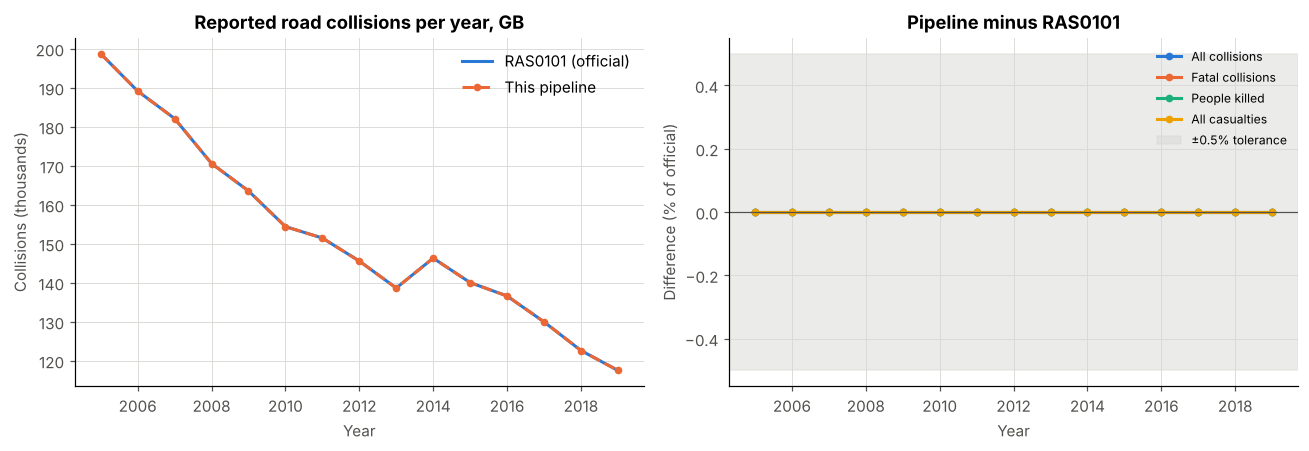

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(collision_table.index, collision_table["ras0101"] / 1000, label="RAS0101 (official)")
ax.plot(collision_table.index, collision_table["pipeline"] / 1000, linestyle="--", marker="o",
        markersize=4, label="This pipeline")
ax.set_title("Reported road collisions per year, GB")
ax.set_ylabel("Collisions (thousands)")
ax.set_xlabel("Year")
ax.legend()

ax = axes[1]
pivot = recon.pivot(index="year", columns="measure", values="pct_difference")
for label in ["All collisions", "Fatal collisions", "People killed", "All casualties"]:
    ax.plot(pivot.index, pivot[label], marker="o", markersize=4, label=label)
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.axhspan(-0.5, 0.5, color="#d9d9d6", alpha=0.5, label="±0.5% tolerance")
ax.set_title("Pipeline minus RAS0101")
ax.set_ylabel("Difference (% of official)")
ax.set_xlabel("Year")
ax.legend(fontsize=8)
fig.tight_layout()
evaluate.save_fig(fig, "01_reconciliation_collisions")
plt.show()

23:14:24 INFO src.evaluate: Saved figure reports/figures/01_ksi_collisions_adjusted_vs_unadjusted.png


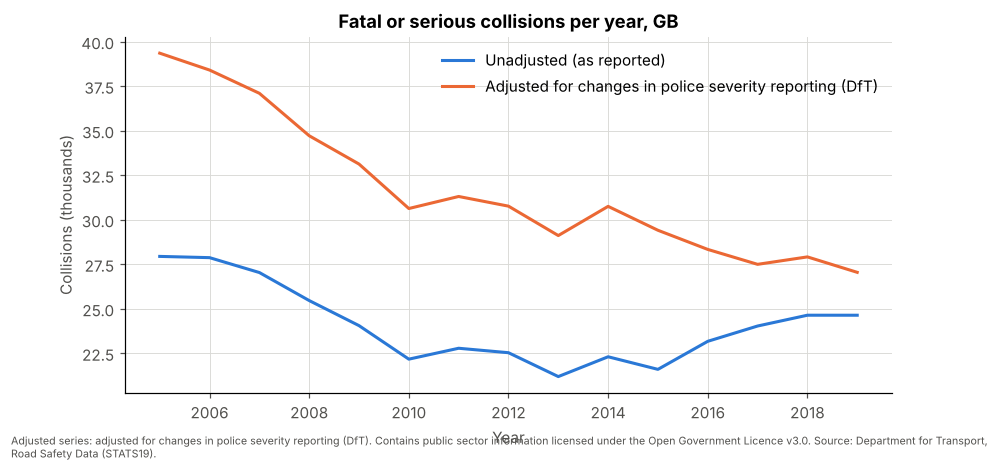

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(yearly.index, yearly["ksi_collisions"] / 1000, label="Unadjusted (as reported)")
ax.plot(yearly.index, yearly["ksi_collisions_adjusted"] / 1000,
        label="Adjusted for changes in police severity reporting (DfT)")
ax.set_title("Fatal or serious collisions per year, GB")
ax.set_ylabel("Collisions (thousands)")
ax.set_xlabel("Year")
ax.legend()
fig.text(0.01, -0.03, f"Adjusted series: {config.SEVERITY_ADJUSTED_FOOTNOTE}. {config.ATTRIBUTION}",
         fontsize=7, color="#52514e", wrap=True)
evaluate.save_fig(fig, "01_ksi_collisions_adjusted_vs_unadjusted")
plt.show()

## Explaining any gaps

The tables above print the size of every difference. Possible reasons for a non-zero gap:

- **DfT revisions.** The open-data CSV is the latest revised version of every year. The
  data guide lists record-level changes (`historical_revisions`). A RAS table published at a
  different time can differ slightly. Use RAS0101 from the same release as the CSV
  (`DOWNLOAD_LOG.json` records both download dates).
- **De-duplication.** Rows dropped as duplicate collision indexes are listed in the cleaning
  log above. If the count is non-zero and the pipeline is *below* RAS0101 by the same amount,
  the duplicates were real records with a reused index, not copies.
- **Casualty linkage.** Casualties are kept only if their collision survived cleaning, so a
  casualty gap can come from collision-level drops.
- **Adjusted serious.** The adjusted figures are sums of probabilities, so they are not
  integers. Small differences can come from rounding in the published table.

**Interpretation of this run:** there is no gap to explain. The CSV and RAS0101 come from the
same DfT release (both downloaded on 2026-10-02), the cleaning log shows 0 duplicate collision
indexes and 0 duplicate casualty rows, and no collisions were dropped between the study-window
filter and the output. The pipeline reproduces the official totals exactly, including the
DfT-adjusted fatal-or-serious count (475,482.245 in both over 2005-2019).